# Advertising-based sales prediction

The 200-row Advertising.csv dataset is downloaded from the Kaggle source linked in the official task. Predict sales from TV, radio and newspaper advertising. The CSV index is excluded. All predictors and targets are numeric and checked for missing cells. An 80/20 split (160 training, 40 test) is used; a mean-sales baseline is included. Five-fold cross-validation reports training-only MAE, and a linear regression is evaluated once on the test data.

The data has no time index, target-segment field, or campaign ordering. This is a cross-sectional prediction exercise for comparable observations, not a demonstrated forecast of future periods. Predictor units are not defined on the Kaggle page, so no currency or monetary return is asserted. Raw regression coefficients are associations conditional on the other inputs, not evidence that spending causes sales. TV/radio associations are stronger than newspaper in this fit. A sensible next step is a controlled campaign experiment, not automatically reallocating a budget. Do not extrapolate beyond observed spend ranges. The source page lists its license as unknown; raw CSV data is not included in the review archive or proposed GitHub repository. Download access does not settle redistribution rights.

Prepared with AI assistance for review. This notebook has been run, but no internship submission is claimed.

## Reproducible implementation

The source below uses seed 42, a training-only validation process and a held-out test set. Install requirements.txt before running. Run all cells from this project folder.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
 roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
 RocCurveDisplay, mean_absolute_error, mean_squared_error, r2_score)
BASE=Path.cwd()
OUT=BASE/"results"
OUT.mkdir(exist_ok=True)
SEED=42

def classify(X, y, names, title):
    assert len(X)==len(y) and not pd.Series(y).isna().any()
    # Exclude contradictory labels for identical feature profiles, then collapse duplicates.
    frame=X.reset_index(drop=True).copy()
    frame["__target"]=np.asarray(y)
    keys=list(X.columns)
    conflicts=frame.groupby(keys,dropna=False)["__target"].transform("nunique")>1
    raw_rows=len(frame)
    frame=frame.loc[~conflicts].drop_duplicates(subset=keys).reset_index(drop=True)
    y=frame.pop("__target").to_numpy()
    X=frame
    quality={"input_rows":raw_rows,"conflicting_profile_rows_removed":int(conflicts.sum()),"duplicate_rows_removed":raw_rows-int(conflicts.sum())-len(frame),"analysis_rows":len(frame)}
    (OUT/"data_quality.json").write_text(json.dumps(quality,indent=2))
    indices=np.arange(len(y))
    train_idx,test_idx=train_test_split(indices,test_size=.2,stratify=y,random_state=SEED)
    assert not set(train_idx)&set(test_idx)
    Xtrain,Xtest=X.iloc[train_idx],X.iloc[test_idx]
    ytrain,ytest=np.asarray(y)[train_idx],np.asarray(y)[test_idx]
    models={"baseline":DummyClassifier(strategy="most_frequent"),
            "logistic":make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),LogisticRegression(max_iter=3000,random_state=SEED)),
            "forest":make_pipeline(SimpleImputer(strategy="median"),RandomForestClassifier(n_estimators=120,min_samples_leaf=4,class_weight="balanced",random_state=SEED,n_jobs=2))}
    multiclass=len(names)>2
    scoring="f1_macro" if multiclass else "roc_auc"
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    cvresults={}
    for name,model in models.items():
        scores=cross_val_score(model,Xtrain,ytrain,cv=cv,scoring=scoring,n_jobs=1)
        cvresults[name]={"mean":float(scores.mean()),"std":float(scores.std())}
    winner=max((k for k in models if k!="baseline"),key=lambda k:cvresults[k]["mean"])
    rows=[]
    for name in ["baseline",winner]:
        model=models[name].fit(Xtrain,ytrain)
        pred=model.predict(Xtest)
        p=model.predict_proba(Xtest)
        avg="macro" if multiclass else "binary"
        row={"model":name,"accuracy":accuracy_score(ytest,pred),"precision":precision_score(ytest,pred,average=avg,zero_division=0),"recall":recall_score(ytest,pred,average=avg,zero_division=0),"f1":f1_score(ytest,pred,average=avg,zero_division=0)}
        if not multiclass:
            row.update(roc_auc=roc_auc_score(ytest,p[:,1]),average_precision=average_precision_score(ytest,p[:,1]))
        rows.append(row)
        if name==winner:
            fig,ax=plt.subplots(figsize=(6,5))
            ConfusionMatrixDisplay.from_predictions(ytest,pred,display_labels=names,ax=ax,colorbar=False,cmap="Blues")
            ax.set_title(title+" | held-out test")
            fig.tight_layout(); fig.savefig(OUT/"confusion_matrix.png",dpi=160);plt.close(fig)
            if not multiclass:
                fig,ax=plt.subplots(figsize=(6,5)); RocCurveDisplay.from_predictions(ytest,p[:,1],ax=ax)
                ax.plot([0,1],[0,1],"--",color="gray");ax.set_title(title+" | ROC");ax.legend([f"ROC-AUC = {roc_auc_score(ytest,p[:,1]):.4f}"],loc="lower right")
                fig.tight_layout();fig.savefig(OUT/"roc_curve.png",dpi=160);plt.close(fig)
            pd.DataFrame({"source_row":test_idx,"actual":ytest,"predicted":pred}).to_csv(OUT/"test_predictions.csv",index=False)
    result={"rows":len(y),"train_rows":len(train_idx),"test_rows":len(test_idx),"seed":SEED,"positive_class":None if multiclass else names[1],"cv_metric":scoring,"cv_train_only":cvresults,"selected_model":winner,"held_out":rows,"class_counts":pd.Series(y).value_counts().sort_index().to_dict()}
    (OUT/"metrics.json").write_text(json.dumps(result,indent=2))
    pd.DataFrame(rows).to_csv(OUT/"metrics.csv",index=False)
    print(json.dumps(result,indent=2))
    return result

import urllib.request,zipfile,io,hashlib
DATA=BASE/"data";DATA.mkdir(exist_ok=True)
file=DATA/"Advertising.csv"
url="https://www.kaggle.com/api/v1/datasets/download/bumba5341/advertisingcsv"
if not file.exists():
    req=urllib.request.Request(url,headers={"User-Agent":"Educational reproducibility project"})
    raw=urllib.request.urlopen(req,timeout=90).read()
    archive=zipfile.ZipFile(io.BytesIO(raw))
    entry=next(n for n in archive.namelist() if n.lower().endswith(".csv"))
    file.write_bytes(archive.read(entry))
df=pd.read_csv(file)
df.columns=[c.strip().lower() for c in df.columns]
X=df[["tv","radio","newspaper"]]
y=df["sales"]
assert len(df)==200 and not X.isna().any().any() and not y.isna().any()
Xtrain,Xtest,ytrain,ytest=train_test_split(X,y,test_size=.2,random_state=SEED)
models={"baseline":DummyRegressor(strategy="mean"),"linear":LinearRegression()}
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
cvmae=-cross_val_score(models["linear"],Xtrain,ytrain,cv=cv,scoring="neg_mean_absolute_error")
rows=[]
for name,model in models.items():
    model.fit(Xtrain,ytrain);pred=model.predict(Xtest)
    rows.append({"model":name,"mae":mean_absolute_error(ytest,pred),"rmse":float(np.sqrt(mean_squared_error(ytest,pred))),"r2":r2_score(ytest,pred)})
    if name=="linear":
        pd.DataFrame({"source_row":ytest.index,"actual":ytest,"predicted":pred,"residual":ytest-pred}).to_csv(OUT/"test_predictions.csv",index=False)
        fig,axes=plt.subplots(1,2,figsize=(10,4.5))
        axes[0].scatter(ytest,pred,color="#2563eb");lo=min(ytest.min(),pred.min());hi=max(ytest.max(),pred.max());axes[0].plot([lo,hi],[lo,hi],"--",color="gray")
        axes[0].set(xlabel="Actual sales",ylabel="Predicted sales",title="Held-out predictions")
        axes[1].scatter(pred,ytest-pred,color="#7c3aed");axes[1].axhline(0,color="gray",linestyle="--")
        axes[1].set(xlabel="Predicted sales",ylabel="Residual",title="Held-out residuals")
        fig.tight_layout();fig.savefig(OUT/"evaluation.png",dpi=160);plt.close(fig)
        coefficients=dict(zip(X.columns,model.coef_.tolist()))
result={"rows":len(df),"train_rows":len(Xtrain),"test_rows":len(Xtest),"seed":SEED,"cv_train_only_mae_mean":float(cvmae.mean()),"cv_train_only_mae_std":float(cvmae.std()),"held_out":rows,"coefficients":coefficients,"intercept":float(models["linear"].intercept_),"source_sha256":hashlib.sha256(file.read_bytes()).hexdigest()}
(OUT/"metrics.json").write_text(json.dumps(result,indent=2));pd.DataFrame(rows).to_csv(OUT/"metrics.csv",index=False);print(json.dumps(result,indent=2))


{
  "rows": 200,
  "train_rows": 160,
  "test_rows": 40,
  "seed": 42,
  "cv_train_only_mae_mean": 1.2370762380297964,
  "cv_train_only_mae_std": 0.1632001711142684,
  "held_out": [
    {
      "model": "baseline",
      "mae": 4.9625,
      "rmse": 5.631496248777939,
      "r2": -0.004757260886999015
    },
    {
      "model": "linear",
      "mae": 1.4607567168117606,
      "rmse": 1.7815996615334502,
      "r2": 0.899438024100912
    }
  ],
  "coefficients": {
    "tv": 0.044729517468716326,
    "radio": 0.1891950542343766,
    "newspaper": 0.0027611143413672056
  },
  "intercept": 2.9790673381226256,
  "source_sha256": "69104adc017e75d7019f61fe66ca2eb4ab014ee6f2a9b39b452943f209352010"
}


## Read the result

| Model | mae | rmse | r2 |
|---|---:|---:|---:|
| baseline | 4.9625 | 5.6315 | -0.0048 |
| linear | 1.4608 | 1.7816 | 0.8994 |


Do not confuse a good benchmark score with real-world validation. Compare with the baseline and read the limits above.

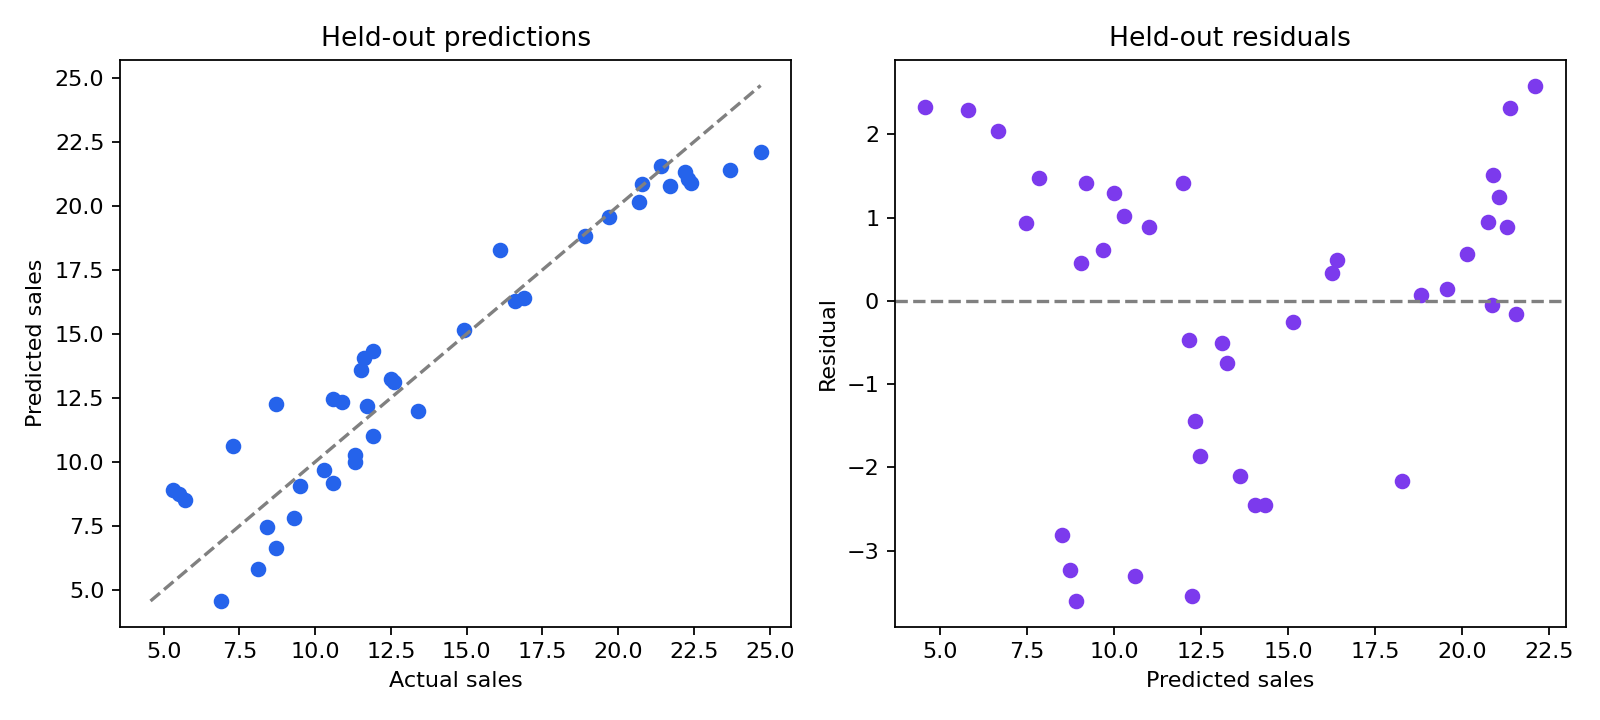

In [2]:
from IPython.display import display, Image
for image in sorted(OUT.glob("*.png")):
    display(Image(filename=str(image)))

## Sources and next steps

https://www.kaggle.com/datasets/bumba5341/advertisingcsv

Review the README, rerun the tests and practice explaining the work before recording the required video. No LinkedIn post, GitHub publication or submission has been made by this notebook.